<a href="https://colab.research.google.com/github/JonathanDP02/244107020197-Pembelajaran-Mesin/blob/main/JS13_Implementasi_Dataset_Praktikum_3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.optimizers import Adam

In [2]:
# Google Colab: unggah file Sleep_health_and_lifestyle_dataset(1).csv
try:
    from google.colab import files
    uploaded = files.upload()
    nama_file = next(iter(uploaded))
except ImportError:
    nama_file = "Sleep_health_and_lifestyle_dataset(1).csv"

data = pd.read_csv(nama_file)
print("Ukuran dataset:", data.shape)
display(data.head())

Saving Sleep_health_and_lifestyle_dataset(1).csv to Sleep_health_and_lifestyle_dataset(1).csv
Ukuran dataset: (374, 13)


,Person ID,Gender,Age,Occupation,Sleep Duration,Quality of Sleep,Physical Activity Level,Stress Level,BMI Category,Blood Pressure,Heart Rate,Daily Steps,Sleep Disorder
0,1,Male,27,Software Engineer,6.1,6,42,6,Overweight,126/83,77,4200,NaN
1,2,Male,28,Doctor,6.2,6,60,8,Normal,125/80,75,10000,NaN
2,3,Male,28,Doctor,6.2,6,60,8,Normal,125/80,75,10000,NaN
3,4,Male,28,Sales Representative,5.9,4,30,8,Obese,140/90,85,3000,Sleep Apnea
4,5,Male,28,Sales Representative,5.9,4,30,8,Obese,140/90,85,3000,Sleep Apnea


In [3]:
data = data.copy()

# Isi target kategori yang kosong agar dapat dijadikan fitur
data["Sleep Disorder"] = data["Sleep Disorder"].fillna("No Disorder")

# Pisahkan tekanan darah menjadi dua fitur numerik
bp = data["Blood Pressure"].str.extract(r"(?P<Systolic>\d+)\s*/\s*(?P<Diastolic>\d+)")
data["Systolic"] = pd.to_numeric(bp["Systolic"], errors="coerce")
data["Diastolic"] = pd.to_numeric(bp["Diastolic"], errors="coerce")

# Person ID tidak digunakan sebagai fitur prediksi
data = data.drop(columns=["Person ID", "Blood Pressure"])

# Encoding seluruh fitur kategorikal
data = pd.get_dummies(
    data,
    columns=["Gender", "Occupation", "BMI Category", "Sleep Disorder"],
    dtype=int
)

data = data.dropna().reset_index(drop=True)
print("Ukuran setelah preprocessing:", data.shape)
display(data.head())

Ukuran setelah preprocessing: (374, 29)


,Age,Sleep Duration,Quality of Sleep,Physical Activity Level,Stress Level,Heart Rate,Daily Steps,Systolic,Diastolic,Gender_Female,...,Occupation_Scientist,Occupation_Software Engineer,Occupation_Teacher,BMI Category_Normal,BMI Category_Normal Weight,BMI Category_Obese,BMI Category_Overweight,Sleep Disorder_Insomnia,Sleep Disorder_No Disorder,Sleep Disorder_Sleep Apnea
0,27,6.1,6,42,6,77,4200,126,83,0,...,0,1,0,0,0,0,1,0,1,0
1,28,6.2,6,60,8,75,10000,125,80,0,...,0,0,0,1,0,0,0,0,1,0
2,28,6.2,6,60,8,75,10000,125,80,0,...,0,0,0,1,0,0,0,0,1,0
3,28,5.9,4,30,8,85,3000,140,90,0,...,0,0,0,0,0,1,0,0,0,1
4,28,5.9,4,30,8,85,3000,140,90,0,...,0,0,0,0,0,1,0,0,0,1


In [4]:
X = data.drop(columns=["Quality of Sleep"]).to_numpy(dtype=float)
y = data["Quality of Sleep"].to_numpy(dtype=float).reshape(-1, 1)

print("Bentuk X:", X.shape)
print("Bentuk y:", y.shape)

Bentuk X: (374, 28)
Bentuk y: (374, 1)


In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

X_train: (299, 28)
X_test: (75, 28)


In [6]:
scaler_X = StandardScaler()
scaler_y = StandardScaler()

X_train_scaled = scaler_X.fit_transform(X_train)
X_test_scaled = scaler_X.transform(X_test)

y_train_scaled = scaler_y.fit_transform(y_train)
y_test_scaled = scaler_y.transform(y_test)

print("Normalisasi selesai.")

Normalisasi selesai.


In [7]:
tf.keras.utils.set_random_seed(42)

model = Sequential([
    tf.keras.layers.Input(shape=(X_train_scaled.shape[1],)),
    Dense(64, activation="relu"),
    Dense(32, activation="relu"),
    Dense(1)
])

model.compile(
    optimizer=Adam(learning_rate=1e-3),
    loss="mse",
    metrics=["mae"]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         1,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,969 (15.50 KB)

 Trainable params: 3,969 (15.50 KB)

 Non-trainable params: 0 (0.00 B)

In [8]:
history = model.fit(
    X_train_scaled,
    y_train_scaled,
    validation_data=(X_test_scaled, y_test_scaled),
    epochs=200,
    batch_size=32,
    verbose=1
)

Epoch 1/200
10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 41ms/step - loss: 0.7313 - mae: 0.7104 - val_loss: 0.3504 - val_mae: 0.4767
Epoch 2/200
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 0.2495 - mae: 0.3719 - val_loss: 0.1845 - val_mae: 0.2763
Epoch 3/200
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 0.1088 - mae: 0.2316 - val_loss: 0.1130 - val_mae: 0.1804
Epoch 4/200
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - loss: 0.0655 - mae: 0.1504 - val_loss: 0.0819 - val_mae: 0.1360
Epoch 5/200
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 0.0475 - mae: 0.1217 - val_loss: 0.0720 - val_mae: 0.1222
Epoch 6/200
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 0.0362 - mae: 0.1024 - val_loss: 0.0614 - val_mae: 0.1113
Epoch 7/200
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - loss: 0.0289 - mae: 0.0860 - val_loss: 0.0561 - val_mae: 0.1070
Epoch 8/200
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 0.0248 - mae: 0.0791 - val_loss: 0.0557 - val_mae: 0.1015
Epoch 9/200
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - lo

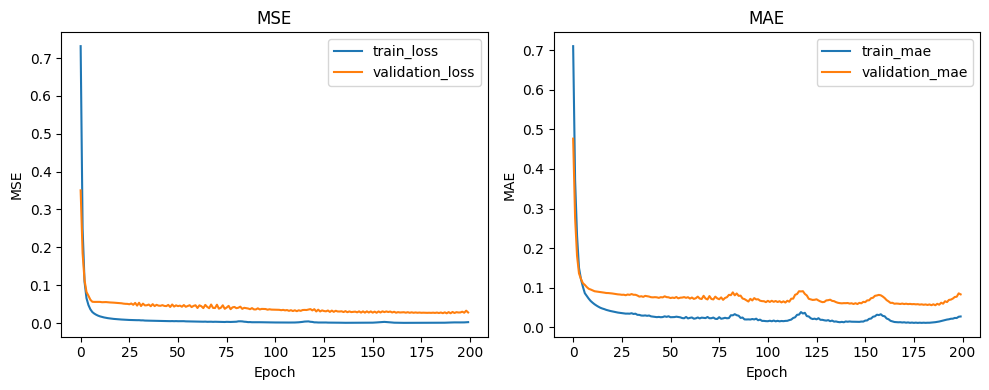

In [9]:
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["loss"], label="train_loss")
plt.plot(history.history["val_loss"], label="validation_loss")
plt.legend()
plt.title("MSE")
plt.xlabel("Epoch")
plt.ylabel("MSE")

plt.subplot(1, 2, 2)
plt.plot(history.history["mae"], label="train_mae")
plt.plot(history.history["val_mae"], label="validation_mae")
plt.legend()
plt.title("MAE")
plt.xlabel("Epoch")
plt.ylabel("MAE")

plt.tight_layout()
plt.show()

In [10]:
test_loss, test_mae = model.evaluate(X_test_scaled, y_test_scaled, verbose=0)
print(f"Test MSE (skala standar): {test_loss:.4f}")
print(f"Test MAE (skala standar): {test_mae:.4f}")

Test MSE (skala standar): 0.0279
Test MAE (skala standar): 0.0831


In [11]:
prediksi_scaled = model.predict(X_test_scaled, verbose=0)

# Kembalikan target prediksi dan aktual ke skala 1–10
prediksi = scaler_y.inverse_transform(prediksi_scaled)
aktual = scaler_y.inverse_transform(y_test_scaled)

rmse = np.sqrt(mean_squared_error(aktual, prediksi))
mae = mean_absolute_error(aktual, prediksi)
mse = mean_squared_error(aktual, prediksi)

print(f"MSE:  {mse:.4f}")
print(f"RMSE: {rmse:.4f}")
print(f"MAE:  {mae:.4f}")

hasil_prediksi = pd.DataFrame({
    "Quality of Sleep Aktual": aktual.flatten(),
    "Quality of Sleep Prediksi": prediksi.flatten()
})
display(hasil_prediksi.head(15))

MSE:  0.0389
RMSE: 0.1972
MAE:  0.0981


,Quality of Sleep Aktual,Quality of Sleep Prediksi
0,9.0,9.023777
1,6.0,5.909726
2,6.0,5.937436
3,9.0,9.023777
4,6.0,5.916661
5,6.0,5.888160
6,6.0,5.925455
7,8.0,8.006695
8,9.0,9.003130
9,8.0,8.029635


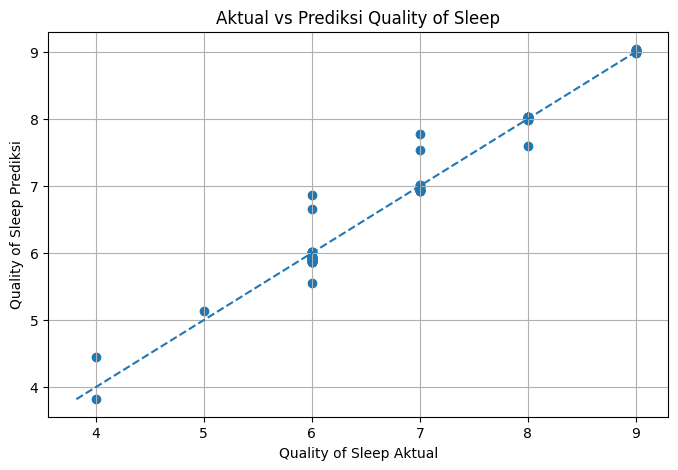

In [12]:
plt.figure(figsize=(8, 5))
plt.scatter(aktual, prediksi)
plt.xlabel("Quality of Sleep Aktual")
plt.ylabel("Quality of Sleep Prediksi")
plt.title("Aktual vs Prediksi Quality of Sleep")

batas_min = min(aktual.min(), prediksi.min())
batas_max = max(aktual.max(), prediksi.max())
plt.plot([batas_min, batas_max], [batas_min, batas_max], linestyle="--")
plt.grid(True)
plt.show()